# КТ1 — кому отдать аварийный резерв выездной службы

Выездная служба чинит банкоматы и прочее оборудование. Если сорвать SLA, будет штраф, простой клиента и повторный выезд. Усилить можно только 20% заявок (каждую пятую).

**Что делает система.** Когда приходит новая заявка, модель считает вероятность срыва SLA. Самые рисковые 20% заявок идут в аварийный резерв.
**Цена ошибок.** Пропустить сложную заявку плохо: штраф + простой + второй выезд. Усилить лишнюю не так страшно: просто потратили одно место очереди.

Задача: проверить, лучше ли небольшая MLP простой линейной модели при очереди 20%.

In [1]:
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import recall_score, roc_auc_score, roc_curve

# загружаю данные, смотрю размер и долю нарушений
df = pd.read_csv('data/КТ1_заявки_выездной_службы.csv')
display(df.head())
print('размер данных:', df.shape)
print('доля нарушений SLA:', f'{df.sla_breach.mean():.1%}')
display(df.describe().round(1))

,request_id,distance_km,priority,spare_part_available,engineer_experience_years,equipment_age_years,repeat_request,regional_load_pct,sla_breach
0,REQ-0001,108,низкий,1,8,12,0,48,0
1,REQ-0002,80,низкий,1,2,3,0,91,1
2,REQ-0003,111,средний,1,3,15,0,49,0
3,REQ-0004,109,низкий,0,9,1,0,43,1
4,REQ-0005,10,низкий,0,3,10,0,86,0


размер данных: (1500, 9)
доля нарушений SLA: 37.5%


,distance_km,spare_part_available,engineer_experience_years,equipment_age_years,repeat_request,regional_load_pct,sla_breach
count,1500.0,1500.0,1500.0,1500.0,1500.0,1500.0,1500.0
mean,62.0,0.7,5.5,8.3,0.2,67.5,0.4
std,33.4,0.5,2.6,4.4,0.4,18.7,0.5
min,2.0,0.0,1.0,1.0,0.0,35.0,0.0
25%,33.8,0.0,3.0,4.0,0.0,52.0,0.0
50%,64.0,1.0,5.0,8.0,0.0,67.0,0.0
75%,90.0,1.0,8.0,12.0,0.0,84.0,1.0
max,120.0,1.0,10.0,16.0,1.0,100.0,1.0


Проверил данные: 1500 заявок, 9 колонок, пропусков нет. Нарушений 37.5%.

Важный момент, который я сначала не учел: нарушений 37.5%, а мест в очереди всего 20%. Значит даже идеальная модель найдет максимум 20 / 37.5 = **53.6%** нарушений. Так что recall надо сравнивать с 53%, а не со 100%.

## Шаг 1. Что значит очередь 20%

Резерв дают только каждой пятой заявке. Модель просто сортирует заявки по риску, порог не подбираю — беру верхние 20% скора. Метрика recall: сколько всех нарушений поймали в очередь.

In [2]:
target = 'sla_breach'
num = ['distance_km', 'engineer_experience_years', 'equipment_age_years', 'repeat_request', 'regional_load_pct']
cat = ['priority', 'spare_part_available']

train_df, test_df = train_test_split(df, test_size=.25, random_state=42, stratify=df[target])
X_train, X_test = train_df[num + cat], test_df[num + cat]
y_train, y_test = train_df[target], test_df[target]

prep = ColumnTransformer([('num', StandardScaler(), num),
                          ('cat', OneHotEncoder(handle_unknown='ignore'), cat)])

def top20_report(name, model):
    model.fit(X_train, y_train)
    p = model.predict_proba(X_test)[:, 1]
    cutoff = np.quantile(p, .80)  # порог не подбираю: очередь всегда 20%, поэтому просто 80-й перцентиль
    pred = (p >= cutoff).astype(int)
    hits = int((pred & y_test.values).sum())
    print(f'{name:14} найдено нарушений: {recall_score(y_test, pred):.0%} ({hits} из {int(y_test.sum())})   '
          f'очередь: {pred.mean():.0%}   точность очереди: {hits/max(pred.sum(),1):.0%}   AUC: {roc_auc_score(y_test, p):.3f}')
    return model, p, pred

baseline = Pipeline([('prep', prep), ('model', LogisticRegression(max_iter=1000, random_state=42))])
small = Pipeline([('prep', prep), ('model', MLPClassifier((12,), max_iter=600, early_stopping=True, random_state=42))])
wide = Pipeline([('prep', prep), ('model', MLPClassifier((32, 16), max_iter=600, early_stopping=True, random_state=42))])

results = {}
for name, m in [('Baseline', baseline), ('MLP compact', small), ('MLP wide', wide)]:
    results[name] = top20_report(name, m)

# сохраняю сплит для программы на Rust
train_df.to_csv('data/train.csv', index=False)
test_df.to_csv('data/test.csv', index=False)
print('\nразбиение сохранено: data/train.csv, data/test.csv')

Baseline       найдено нарушений: 46% (65 из 140)   очередь: 20%   точность очереди: 87%   AUC: 0.843


MLP compact    найдено нарушений: 36% (50 из 140)   очередь: 20%   точность очереди: 67%   AUC: 0.753


MLP wide       найдено нарушений: 49% (68 из 140)   очередь: 20%   точность очереди: 91%   AUC: 0.883

разбиение сохранено: data/train.csv, data/test.csv


### Результаты шага 1 (random_state=42)

| модель | параметров | recall | точность очереди | AUC |
|---|---|---|---|---|
| случайный отбор | - | ~37% | ~37% | 0.5 |
| Baseline (логрегрессия) | 10 | 46% (65 из 140) | 87% | 0.843 |
| MLP compact (12,) | 133 | 36% (50 из 140) | 67% | 0.753 |
| MLP wide (32,16) | 865 | 49% (68 из 140) | 91% | 0.883 |

Потолок 53.6% (75 мест на 140 нарушений).

Baseline уже неплохо работает. MLP wide чуть лучше. А MLP compact вообще сработала хуже базлайна.

In [3]:
# проверяю, сильно ли результат зависит от random_state
print('recall в очереди 20% при разных random_state:')
for name, mk in [('MLP compact', lambda s: MLPClassifier((12,), max_iter=600, early_stopping=True, random_state=s)),
                 ('MLP wide',     lambda s: MLPClassifier((32, 16), max_iter=600, early_stopping=True, random_state=s))]:
    vals = []
    for s in (7, 42, 2024):
        m = Pipeline([('prep', prep), ('model', mk(s))])
        m.fit(X_train, y_train)
        p = m.predict_proba(X_test)[:, 1]
        vals.append(recall_score(y_test, (p >= np.quantile(p, .80)).astype(int)))
    print(f'  {name:12}: ' + '   '.join(f'seed {s}: {v:.0%}' for s, v in zip((7, 42, 2024), vals))
          + f'   (разброс {max(vals) - min(vals):.0%})')

recall в очереди 20% при разных random_state:


  MLP compact : seed 7: 47%   seed 42: 36%   seed 2024: 44%   (разброс 11%)


  MLP wide    : seed 7: 48%   seed 42: 49%   seed 2024: 36%   (разброс 12%)


## Шаг 2. Объяснение результата

**Кто нашел больше:** MLP wide, 49% против 46% у baseline. Это всего +3 заявки из 140 нарушений.

**Почему более широкая сеть не обязана победить:**
1. Данные в основном линейные. Коэффициенты baseline показывают, что главный вклад дают высокий приоритет, дальность и отсутствие запчасти. Нелинейных сочетаний мало, широкой сети почти нечего добавлять.
2. У MLP wide 865 параметров, а обучающих заявок всего 1125. По-моему, она частично запоминает шум, а early stopping это только прячет.
3. Recall top-20% зависит от порядка всего 75 заявок около порога. Чуть сдвинулись веса — состав очереди другой. Проверка выше это показывает: MLP wide на трех seed дает 48%, 49% и 36%. Один запуск ничего не доказывает.
4. Всем тесно под потолком 53.6%. Разница между моделями — это борьба за пару процентов на пограничных заявках.

In [4]:
# ошибки лучшей модели: пропуски и ложные тревоги
best_name = 'MLP wide'
model, p, pred = results[best_name]
audit = test_df.copy()
audit['fact'] = y_test.values
audit['risk'] = p
audit['decision'] = pred
errors = audit[audit.fact != audit.decision]

cols = ['request_id', 'distance_km', 'priority', 'spare_part_available', 'engineer_experience_years',
        'equipment_age_years', 'repeat_request', 'regional_load_pct', 'risk']
missed = errors[(errors.fact == 1) & (errors.decision == 0)].sort_values('risk').head(4)
false_alarm = errors[(errors.fact == 0) & (errors.decision == 1)].sort_values('risk', ascending=False).head(4)
print(f'всего ошибок у {best_name}: {len(errors)} из 375 (пропусков {int((errors.fact == 1).sum())}, ложных тревог {int((errors.fact == 0).sum())})')
display(missed[cols])
display(false_alarm[cols])

всего ошибок у MLP wide: 79 из 375 (пропусков 72, ложных тревог 7)


,request_id,distance_km,priority,spare_part_available,engineer_experience_years,equipment_age_years,repeat_request,regional_load_pct,risk
260,REQ-0261,11,средний,1,10,3,0,40,0.006228
1463,REQ-1464,22,средний,0,10,12,0,43,0.007160
620,REQ-0621,37,средний,1,5,10,0,88,0.020753
413,REQ-0414,34,низкий,1,3,9,0,52,0.029103


,request_id,distance_km,priority,spare_part_available,engineer_experience_years,equipment_age_years,repeat_request,regional_load_pct,risk
284,REQ-0285,91,высокий,0,5,3,1,91,0.988643
1187,REQ-1188,118,средний,0,4,13,0,83,0.971408
1262,REQ-1263,90,высокий,0,3,5,1,37,0.920148
700,REQ-0701,69,средний,0,4,1,0,80,0.916180


### Разбор ошибок

**Пропуски (нарушение было, а резерв не дали):**

1. **REQ-0261, скор 0.6%** — 11 км, средний приоритет, запчасть есть, инженер 10 лет, техника 3 года, загрузка 40%. Все спокойно, а срыв случился. Наверное, причина вообще не в данных (поломка машины в пути, ошибка диспетчера). Что делать: разбирать такие случаи руками и добавлять признаки (время суток, тип устройства, история клиента).
2. **REQ-1464, скор 0.7%** — 22 км, запчасти нет, но инженер опытный (10 лет) и загрузка низкая (43%). Модель поверила опыту, а запчасти все равно не оказалось. Что делать: вручную смотреть заявки «нет запчасти + техника старше 10 лет».
3. **REQ-0621, скор 2.1%** — 37 км, загрузка региона 88%. Загруженный регион съел время реакции. Что делать: усилить вес загрузки региона, держать резерв людей при загрузке выше 85%.
4. **REQ-0414, скор 2.9%** — низкий приоритет, инженер всего 3 года. Низкий приоритет уронил заявку вниз списка, а молодой инженер не справился. Что делать: наставничество, контроль заявок у инженеров с опытом меньше 3 лет.

**Ложные тревоги (резерв потрачен, все обошлось):**

5. **REQ-0285, скор 98.9%** — 91 км, высокий, запчасти нет, повторная, загрузка 91%. Профиль опасный, но справились (техника новая, 3 года). Это не ошибка, а страховка.
6. **REQ-1188, скор 97.1%** — 118 км, запчасти нет, техника 13 лет. Опять честная ставка, просто повезло. Что делать: ничего, копить статистику.
7. **REQ-1263, скор 92.0%** — 90 км, высокий, повторная, запчасти нет, но регион свободный (37%). Модель не учла, что свободный регион компенсирует дальность. Что делать: добавить сочетание «дальность + загрузка региона» — это как раз тот случай, ради которого нужна MLP.
8. **REQ-0701, скор 91.6%** — 69 км, запчасти нет, загрузка 80%. Обошлось. Принимаю, цена ошибки маленькая.

**Вывод по ошибкам.** Ложные тревоги почти все «по делу» (даль + нет запчасти + высокий приоритет), их цена небольшая. Пропуски — это скрытые причины, которых нет в признаках. То есть надо собирать больше данных, а не строить более сложную сеть.

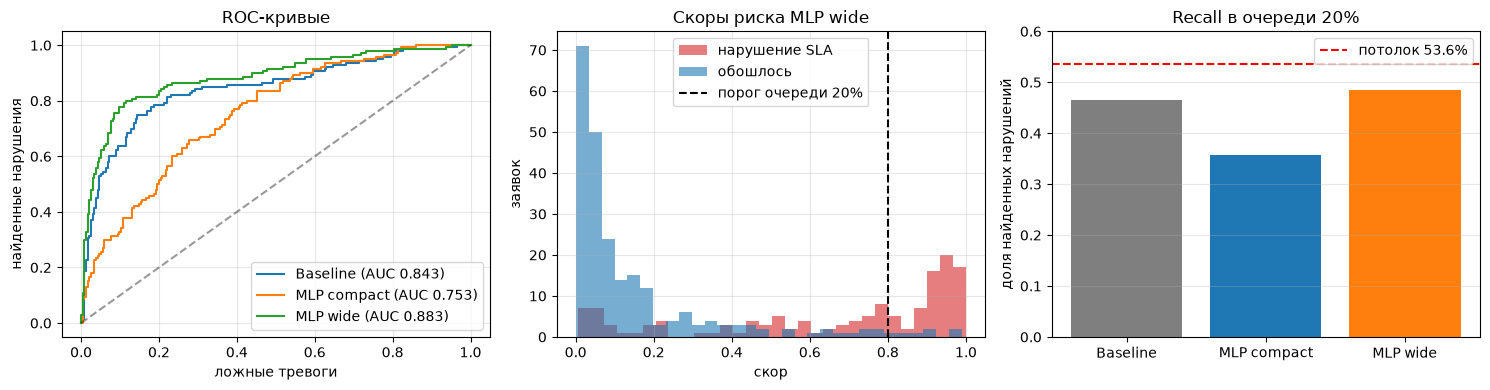

In [5]:
# графики: ROC, распределение скоров, сравнение recall
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for name, (mdl, p, pred) in results.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC {roc_auc_score(y_test, p):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=.4)
axes[0].set(title='ROC-кривые', xlabel='ложные тревоги', ylabel='найденные нарушения')
axes[0].legend(); axes[0].grid(alpha=.3)

_, p_best, _ = results['MLP wide']
for fact, color, label in [(1, 'tab:red', 'нарушение SLA'), (0, 'tab:blue', 'обошлось')]:
    axes[1].hist(p_best[y_test.values == fact], bins=30, alpha=.6, color=color, label=label)
axes[1].axvline(np.quantile(p_best, .80), color='k', ls='--', label='порог очереди 20%')
axes[1].set(title='Скоры риска MLP wide', xlabel='скор', ylabel='заявок')
axes[1].legend(); axes[1].grid(alpha=.3)

names = list(results)
recalls = [recall_score(y_test, (results[n][1] >= np.quantile(results[n][1], .80)).astype(int)) for n in names]
axes[2].bar(names, recalls, color=['tab:gray', 'tab:blue', 'tab:orange'])
axes[2].axhline(75 / 140, color='red', ls='--', label='потолок 53.6%')
axes[2].set(title='Recall в очереди 20%', ylabel='доля найденных нарушений')
axes[2].set_ylim(0, .6); axes[2].legend(); axes[2].grid(alpha=.3, axis='y')

plt.tight_layout()
plt.savefig('img/сравнение_моделей.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
# вклады признаков в baseline
fitted = results['Baseline'][0]
coefs = pd.Series(fitted.named_steps['model'].coef_[0], index=prep.get_feature_names_out())
display(coefs.sort_values(key=abs, ascending=False).round(2).to_frame('вклад'))

,вклад
cat__priority_высокий,1.54
num__distance_km,1.46
cat__spare_part_available_0,0.89
cat__spare_part_available_1,-0.89
cat__priority_средний,-0.77
cat__priority_низкий,-0.77
num__equipment_age_years,-0.38
num__engineer_experience_years,-0.28
num__regional_load_pct,0.27
num__repeat_request,0.23


**Что говорят коэффициенты baseline.** Больше всего риск двигают высокий приоритет (+1.54), дальность (+1.46) и отсутствие запчасти (+0.89). Опыт инженера защищает (-0.28). Странно, что возраст техники тоже защищает (-0.38): может, старую технику чаще обслуживают по регламенту, не знаю.

**Про нелинейность.** Линейной модели хватает на большую часть сигнала, поэтому baseline так близко к MLP. Польза скрытых слоев — в сочетаниях типа «дальность опасна, когда нет запчасти и регион загружен» (это как раз REQ-1263 из разбора ошибок). Прирост MLP wide реальный (AUC 0.843 → 0.883), но маленький по сравнению с шумом от инициализации.

## Шаг 3. Решение о пилоте

> При очереди 20% модель MLP wide находит 49% нарушений (68 из 140) против 46% (65 из 140) у baseline. Рекомендуется **revise**, потому что прирост +2.2 п.п. легко теряется: на другом seed та же сеть дает 36%, то есть хуже базлайна. Выпускать модель, у которой состав очереди меняется на треть от запуска к запуску, нельзя.

Что сделать до go:
1. усреднить несколько MLP (ансамбль) или зафиксировать seed, чтобы разброс был меньше 3 п.п.;
2. добавить признаки из разбора ошибок: время суток, тип устройства, история клиента;
3. запустить пилот на 2–4 недели как подсказку диспетчеру: он видит очередь и скоры, но решает сам. Контроль: точность очереди не ниже 85% и стабильность по неделям.

## Проверка на Rust

Я в основном пишу на Rust, поэтому решил сделать то же самое на нем: вдруг sklearn что-то скрывает. Еще это помогло понять backprop, пока писал его руками.

Что в папке `rust/`:
- polars читает CSV и готовит признаки;
- linfa-logistic делает baseline;
- candle делает MLP 9-12-1, шаг SGD с инерцией написал сам, без готового оптимизатора;
- метрика та же: верхние 20% скора, recall, точность, AUC.

Ноутбук сохраняет `data/train.csv` и `data/test.csv`, Rust их читает, учит модели и пишет `data/rust_metrics.csv` и `data/rust_predictions.csv`. Следующая ячейка запускает Rust прямо из ноутбука и забирает результаты обратно. Пересборка: `cd rust && cargo build --release`.

| модель | recall | точность очереди | AUC |
|---|---|---|---|
| логрегрессия (linfa) | 46.4% | 86.7% | 0.843 |
| MLP 9-12-1 (candle) | 47.1% | 88.0% | 0.864 |

Логрегрессия сошлась со sklearn до десятых, значит и препроцессинг, и метрики посчитаны правильно. MLP на candle чуть слабее sklearn wide (47% против 49%), но это в пределах разброса от инициализации, который я показывал выше.

In [7]:
# запускаю Rust-часть и забираю ее результаты; если бинарника нет, читаю сохраненные файлы
import os, subprocess

bin_path = os.path.join('rust', 'target', 'release', 'kt1-field-reserve')
if os.path.exists(bin_path):
    print('запускаю Rust (linfa + candle) на том же разбиении...')
    out = subprocess.run([bin_path, 'data/train.csv', 'data/test.csv',
                          'data/rust_metrics.csv', 'data/rust_predictions.csv'],
                         capture_output=True, text=True)
    print('\n'.join(out.stdout.strip().splitlines()[-10:]))
else:
    print('бинарника нет, показываю сохраненные результаты из data/rust_metrics.csv')
    print('пересборка: cd rust && cargo build --release')

rust_metrics = pd.read_csv('data/rust_metrics.csv')
display(rust_metrics)

# сравнение решений Rust-MLP и sklearn MLP wide
rust_pred = pd.read_csv('data/rust_predictions.csv')
cmp = rust_pred.merge(audit[['request_id', 'risk', 'decision']].rename(
    columns={'risk': 'risk_sklearn', 'decision': 'decision_sklearn'}), on='request_id')
agree = (cmp.decision == cmp.decision_sklearn).mean()
corr = cmp.risk.corr(cmp.risk_sklearn)
print(f'решения по очереди совпадают в {agree:.0%} заявок, корреляция скоров {corr:.2f}')

запускаю Rust (linfa + candle) на том же разбиении...


  REQ-1311  риск 100.0%  факт: нарушение SLA
  REQ-0622  риск 100.0%  факт: нарушение SLA
  REQ-1176  риск 100.0%  факт: нарушение SLA
  REQ-1392  риск 100.0%  факт: нарушение SLA
  REQ-0437  риск 100.0%  факт: нарушение SLA
  REQ-0402  риск 100.0%  факт: нарушение SLA
  REQ-1483  риск 100.0%  факт: нарушение SLA

метрики записаны: data/rust_metrics.csv
решения MLP записаны: data/rust_predictions.csv


,model,queue_pct,recall_pct,precision_pct,auc
0,случайный отбор,20.0,37.3,37.3,0.500
1,логрегрессия (linfa),20.0,46.4,86.7,0.843
2,MLP 9-12-1 (candle),20.0,47.1,88.0,0.864


решения по очереди совпадают в 88% заявок, корреляция скоров 0.84
